In [3]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## Data Collection

In [4]:
funds = ["FSPTX", "FSELX", "FSCSX", "FSPHX", "FBIOX", "FSMEX", "FPHAX", "FIDSX", "FSRBX", "FSPCX", "FSENX", "FSDAX", "FSRFX", "FSCPX", "FSAVX", "FSRPX", "FDFAX", "FSTCX", "FWRLX"]
prices = yf.download(tickers=funds, start="2015-01-01", end="2026-10-01", auto_adjust=False, progress=False)

In [5]:
prices = prices["Adj Close"]
prices

Ticker,FBIOX,FDFAX,FIDSX,FPHAX,FSAVX,FSCPX,FSCSX,FSDAX,FSELX,FSENX,FSMEX,FSPCX,FSPHX,FSPTX,FSRBX,FSRFX,FSRPX,FSTCX,FWRLX
Date,,,,,,,,,,,,,,,,,,,
2015-01-02,11.000015,46.551407,4.670525,10.712299,20.123480,19.435741,4.505635,6.041415,2.884585,36.330269,16.714161,26.004532,10.029359,4.799391,11.604660,42.423233,4.205564,28.825602,3.914889
2015-01-05,11.020166,46.056801,4.580222,10.622028,19.604448,19.080353,4.434747,5.946351,2.837291,34.780521,16.779015,25.517305,9.970015,4.720871,11.296416,41.462181,4.124608,28.381531,3.837537
2015-01-06,10.810784,45.965557,4.512495,10.556833,19.371328,18.899744,4.365809,5.905756,2.785574,34.280087,16.644989,25.207954,9.872952,4.676361,11.035932,40.682739,4.080834,28.109373,3.798860
2015-01-07,11.174008,46.618637,4.551348,10.757439,19.718815,19.243481,4.386451,5.963821,2.811092,34.280087,16.969240,25.455435,10.130101,4.708274,11.118420,40.833290,4.156614,28.276489,3.833239
2015-01-08,11.334736,47.358147,4.610148,10.963057,20.066298,19.523129,4.462013,6.089203,2.889348,35.038807,17.289173,25.803452,10.312269,4.812408,11.292077,41.719055,4.208389,28.682354,3.893402
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-09-24,29.000000,91.109657,16.469999,34.869999,51.939999,61.090000,24.660000,25.860001,63.730000,90.510002,56.830002,91.459999,29.990000,58.070000,36.110001,112.410004,16.629999,67.925964,15.230000
2026-09-25,28.920000,91.507607,16.610001,35.000000,52.450001,61.259998,24.530001,26.059999,64.379997,89.889999,56.820000,91.919998,29.959999,58.459999,36.509998,113.059998,16.719999,67.727005,15.320000
2026-09-28,28.969999,91.855804,16.410000,34.990002,51.380001,60.459999,24.299999,25.490000,63.840000,89.889999,57.400002,91.730003,30.139999,57.889999,36.000000,112.720001,16.680000,66.851562,15.060000


In [6]:
log_returns = np.log(prices).diff().dropna()
print(log_returns)

Ticker         FBIOX     FDFAX     FIDSX     FPHAX     FSAVX     FSCPX  \
Date                                                                     
2015-01-05  0.001830 -0.010682 -0.019524 -0.008463 -0.026131 -0.018455   
2015-01-06 -0.019183 -0.001983 -0.014897 -0.006157 -0.011962 -0.009511   
2015-01-07  0.033046  0.014108  0.008573  0.018824  0.017779  0.018024   
2015-01-08  0.014282  0.015738  0.012837  0.018934  0.017468  0.014428   
2015-01-09  0.000433 -0.005491 -0.011914 -0.003207 -0.013017 -0.008090   
...              ...       ...       ...       ...       ...       ...   
2026-09-24  0.004839 -0.008373 -0.003031  0.011537 -0.012627 -0.004573   
2026-09-25 -0.002762  0.004358  0.008464  0.003721  0.009771  0.002779   
2026-09-28  0.001727  0.003798 -0.012114 -0.000286 -0.020611 -0.013145   
2026-09-29 -0.003112 -0.006302 -0.004275 -0.004583 -0.000389  0.000827   
2026-09-30 -0.001733 -0.014602 -0.011696 -0.013877 -0.014118 -0.001985   

Ticker         FSCSX     FSDAX     FS

## Performace Summary

### Part 1

In [56]:
mean_returns = log_returns.mean() * 252
volatilities = log_returns.std() * np.sqrt(252)
sharpe_ratio = mean_returns / volatilities

absolute = pd.DataFrame({
    "Mean Return": mean_returns,
    "Volatility": volatilities,
    "Sharpe Ratio": sharpe_ratio,
})

summary_abs = absolute.describe().loc[["min", "25%", "mean", "50%", "75%", "max"]]
summary_abs.index = ["Min", "Q1", "Mean", "Median", "Q3", "Max"]
summary_abs.round(4)

,Mean Return,Volatility,Sharpe Ratio
Min,0.0562,0.1482,0.2480
Q1,0.0828,0.1892,0.3837
Mean,0.1127,0.2238,0.5046
Median,0.1021,0.2167,0.5012
Q3,0.1184,0.2396,0.5756
Max,0.2653,0.3431,0.8405


### Part 2

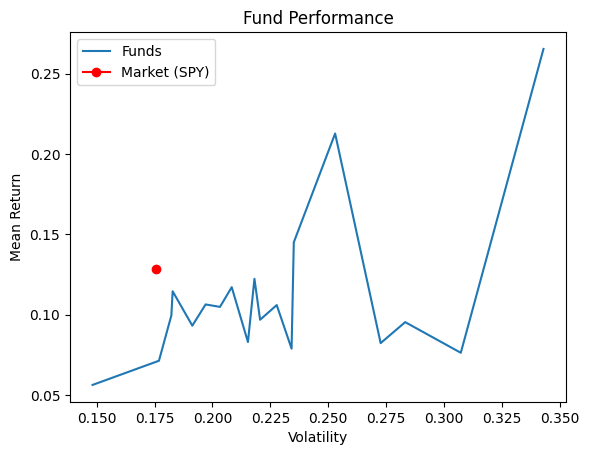

0.7313610350586219


C:\Users\Ctore\AppData\Local\Temp\ipykernel_29576\2825490620.py:28: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  outperforms_market["Sharpe Ratio"] = outperforms_market["Mean Return"] / outperforms_market["Volatility"]


,Mean Return,Volatility,Sharpe Ratio
Ticker,,,
FSCSX,0.144971,0.235144,0.616521
FSPTX,0.212654,0.253010,0.840498
FSELX,0.265296,0.343075,0.773288


In [62]:
market_ticker = ["SPY"]
market_prices = yf.download(market_ticker, start="2015-01-01", end="2026-10-01", auto_adjust=False, progress=False)
market_log_returns = np.log(market_prices).diff().dropna()
market_log_returns = market_log_returns["Adj Close"]

market_mean_return = market_log_returns.mean().iloc[0] * 252
market_volatility = market_log_returns.std().iloc[0] * np.sqrt(252)

fund_metrics = pd.DataFrame({
    "Mean Return": mean_returns,
    "Volatility": volatilites,
})
fund_metrics.sort_values(by="Volatility", inplace=True)
plt.plot(fund_metrics["Volatility"], fund_metrics["Mean Return"], label="Funds")
plt.xlabel("Volatility")
plt.ylabel("Mean Return")
plt.title("Fund Performance")
plt.plot(market_volatility, market_mean_return, color = "red", marker = "o", label="Market (SPY)")
plt.legend()
plt.show()

indices = fund_metrics["Mean Return"] > market_mean_return
outperforms_market = fund_metrics[indices]
outperforms_market

market_sharpe_ratio = market_mean_return / market_volatility
print(market_sharpe_ratio)
outperforms_market["Sharpe Ratio"] = outperforms_market["Mean Return"] / outperforms_market["Volatility"]
outperforms_market

Only the three technology-oriented funds, Software (FSCSX, 14.5%), Technology (FSPTX, 21.3%) and Semiconductors (FSLX, 26.5%), outperform SPY's 12.9% mean return, but each does so with higher volatility (23.5%-34.3% vs. 17.6% for SPY).

### Part 3

#### (a)

In [ ]:
log_returns["SPY"] = market_log_returns.iloc[:, 0]
covariances = log_returns.cov() * 252
covariances["SPY"]
betas = covariances["SPY"] / covariances.loc["SPY", "SPY"]
betas

alphas = mean_returns - betas * market_mean_return
alphas

treynor = (mean_returns) / betas
treynor

tracking_error = log_returns.sub(market_log_returns.iloc[:, 0], axis=0)
tracking_error = tracking_error.std() * np.sqrt(252)

information_ratio = (mean_returns - market_mean_return) / tracking_error
information_ratio

relative = pd.DataFrame({
    "Jensen's Alpha": alphas,
    "Beta": betas,
    "Treynor Ratio": treynor,
    "Tracking Error": tracking_error,
    "Information Ratio": information_ratio,
}).drop("SPY")

summary = relative.describe().loc[["min", "25%", "mean", "50%", "75%", "max"]]
summary.index = ["Min", "Q1", "Mean", "Median", "Q3", "Max"]
summary

Ticker
FBIOX   -0.221190
FDFAX   -0.569804
FIDSX   -0.170942
FPHAX   -0.200906
FSAVX   -0.371396
FSCPX   -0.308491
FSCSX    0.129655
FSDAX   -0.044685
FSELX    0.599996
FSENX   -0.210535
FSMEX   -0.186634
FSPCX   -0.167124
FSPHX   -0.288636
FSPTX    0.682078
FSRBX   -0.165361
FSRFX   -0.367290
FSRPX   -0.106914
FSTCX   -0.422009
FWRLX   -0.169839
SPY           NaN
dtype: float64

(b)

### 4.

#### (a)

In [ ]:
expense = pd.Series({
    "FSPTX": 0.61, "FSELX": 0.60, "FSCSX": 0.61, "FSPHX": 0.62, "FBIOX": 0.62,
    "FSMEX": 0.62, "FPHAX": 0.67, "FIDSX": 0.68, "FSRBX": 0.69, "FSPCX": 0.68,
    "FSENX": 0.65, "FSDAX": 0.63, "FSRFX": 0.68, "FSCPX": 0.69, "FSAVX": 0.78,
    "FSRPX": 0.63, "FDFAX": 0.68, "FSTCX": 0.74, "FWRLX": 0.71,
})

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].scatter(expense[funds], mean_returns[funds])
ax[0].set_xlabel("Expense ratio (%)")
ax[0].set_ylabel("Annual mean return")
ax[0].set_title("Mean Return vs. Expense Ratio")
ax[0].grid(True)

ax[1].scatter(expense[funds], alphas[funds])
ax[1].axhline(0, color="gray", linewidth=0.8)
ax[1].set_xlabel("Expense ratio (%)")
ax[1].set_ylabel("Jensen's alpha (SPY)")
ax[1].set_title("Jensen's Alpha vs. Expense Ratio")
ax[1].grid(True)

for t in funds:
    ax[0].annotate(t, (expense[t], mean_returns[t]), fontsize=7, xytext=(3, 3), textcoords="offset points")
    ax[1].annotate(t, (expense[t], alphas[t]), fontsize=7, xytext=(3, 3), textcoords="offset points")

plt.tight_layout()
plt.savefig("fig_1_4.png", dpi=300)
plt.show()

#### (b)

In [48]:
print("Corr(ER, Mean): ", round(expense[funds].corr(mean_returns[funds]), 4))
print("Corr(ER, Alpha):", round(expense[funds].corr(alphas[funds]), 4))

Corr(ER, Mean):  -0.5501
Corr(ER, Alpha): -0.5391


### 5.

#### Setup

In [66]:
xlk_prices = yf.download("XLK", start="2015-01-01", end="2026-10-01",
                         auto_adjust=False, progress=False)["Adj Close"].squeeze()
xlk_log_returns = np.log(xlk_prices).diff().dropna().reindex(log_returns.index)
xlk_mean_return = xlk_log_returns.mean() * 252

returns_xlk = log_returns[funds].copy()
returns_xlk["XLK"] = xlk_log_returns
cov_xlk = returns_xlk.cov() * 252
betas_xlk = (cov_xlk["XLK"] / cov_xlk.loc["XLK", "XLK"]).drop("XLK")

alphas_xlk = mean_returns - betas_xlk * xlk_mean_return
treynor_xlk = mean_returns / betas_xlk
tracking_error_xlk = log_returns[funds].sub(xlk_log_returns, axis=0).std() * np.sqrt(252)
information_ratio_xlk = (mean_returns - xlk_mean_return) / tracking_error_xlk

#### (a)

In [65]:
relative_xlk = pd.DataFrame({
    "Jensen's Alpha": alphas_xlk,
    "Beta": betas_xlk,
    "Treynor Ratio": treynor_xlk,
    "Tracking Error": tracking_error_xlk,
    "Information Ratio": information_ratio_xlk,
})
summary_xlk = relative_xlk.describe().loc[["min", "25%", "mean", "50%", "75%", "max"]]
summary_xlk.index = ["Min", "Q1", "Mean", "Median", "Q3", "Max"]
display(summary_xlk.round(4))

,Jensen's Alpha,Beta,Treynor Ratio,Tracking Error,Information Ratio
Min,-0.0647,0.3177,0.1117,0.0596,-0.7486
Q1,-0.0329,0.5456,0.1466,0.1627,-0.6535
Mean,-0.0194,0.6449,0.1736,0.1845,-0.4806
Median,-0.0168,0.6089,0.1731,0.1838,-0.5125
Q3,-0.0020,0.6858,0.1934,0.2063,-0.4414
Max,0.0166,1.2688,0.2411,0.2976,0.3633


#### (b)

In [ ]:
compare = pd.DataFrame({
    "Alpha_SPY": alphas[funds],
    "Rank_SPY": alphas[funds].rank(ascending=False).astype(int),
    "Alpha_XLK": alphas_xlk,
    "Rank_XLK": alphas_xlk.rank(ascending=False).astype(int),
}).sort_values("Rank_SPY")
display(compare.round(4))

,Alpha_SPY,Rank_SPY,Alpha_XLK,Rank_XLK
Ticker,,,,
FSELX,0.0643,1,0.0071,3
FSPTX,0.0469,2,0.0044,5
FPHAX,0.0096,3,0.0134,2
FSDAX,-0.0004,4,0.0061,4
FSCSX,-0.0008,5,-0.0292,13
FSPCX,-0.0020,6,0.0166,1
FWRLX,-0.0051,7,-0.0201,12
FSMEX,-0.0118,8,-0.0162,9
FSRPX,-0.0136,9,-0.0186,11
